In [1]:
import numpy as np
import pandas as pd
import sys
import os
from scipy.io import loadmat

# Add src directory to path
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'src')))

from orf_gp.config import GPConfig
from orf_gp.models import OnlineGP
from orf_gp.monitor import OnlineMonitor
from orf_gp.utils import set_global_seeds, get_random_state
from orf_gp.plot_gp import *

In [2]:
# ============================================================
# ★ Change only this line to switch datasets ★
# ============================================================
DATASET = 'concrete'   # Options: 'concrete', 'sarcos', 'energy', 'power', 'kin8nm', 'protein'

# ============================================================
# Dataset Registry
# format:
#   'xls'  → pd.read_excel, x_cols/y_cols as slice or list
#   'mat'  → scipy loadmat, needs mat_key / test_mat_key; train+test merged before split
#   'xlsx' → pd.read_excel (same as xls)
#   'csv'  → pd.read_csv
# ============================================================
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), 'data'))

DATASET_REGISTRY = {
    'concrete': {
        'format'  : 'xls',
        'file'    : 'Concrete_Data.xls',
        'x_cols'  : slice(None, -1),   # first 8 columns
        'y_cols'  : slice(-1, None),   # last column
    },
    'sarcos': {
        'format'       : 'mat',
        'file'         : 'sarcos_inv.mat',
        'mat_key'      : 'sarcos_inv',
        'test_file'    : 'sarcos_inv_test.mat',
        'test_mat_key' : 'sarcos_inv_test',
        'x_cols'       : slice(None, 21),   # 21-dim input
        'y_cols'       : slice(21, None),   # 7-dim output
    },
    'energy': {
        'format'  : 'xlsx',
        'file'    : 'energy+efficiency.xlsx',
        'x_cols'  : slice(None, -2),   # first 8 columns
        'y_cols'  : slice(-2, None),   # last 2 columns (heating + cooling)
    },
    'power': {
        'format'  : 'xlsx',
        'file'    : 'power.xlsx',
        'x_cols'  : slice(None, -1),
        'y_cols'  : slice(-1, None),
    },
    'protein': {
        'format'  : 'csv',
        'file'    : 'protein.csv',
        'x_cols'  : slice(1, None),    # column 0 is the target
        'y_cols'  : slice(None, 1),
    },
}

# ============================================================
# 1. Load raw data (train/test merged into the full set, split inside the loop)
# ============================================================
def load_raw_dataset(name):
    cfg = DATASET_REGISTRY[name]
    fmt = cfg['format']

    if fmt in ('xls', 'xlsx'):
        df  = pd.read_excel(os.path.join(DATA_DIR, cfg['file']))
        X   = df.iloc[:, cfg['x_cols']].values.astype(np.float64)
        y   = df.iloc[:, cfg['y_cols']].values.astype(np.float64)

    elif fmt == 'mat':
        train = loadmat(os.path.join(DATA_DIR, cfg['file']))[cfg['mat_key']]
        test  = loadmat(os.path.join(DATA_DIR, cfg['test_file']))[cfg['test_mat_key']]
        data  = np.vstack([train, test])   # merge into the full set
        X     = data[:, cfg['x_cols']].astype(np.float64)
        y     = data[:, cfg['y_cols']].astype(np.float64)

    elif fmt == 'csv':
        df  = pd.read_csv(os.path.join(DATA_DIR, cfg['file']))
        X   = df.iloc[:, cfg['x_cols']].values.astype(np.float64)
        y   = df.iloc[:, cfg['y_cols']].values.astype(np.float64)

    else:
        raise ValueError(f"Unknown format: {fmt}")

    if y.ndim == 1:
        y = y[:, None]

    return X, y

X_all, y_all = load_raw_dataset(DATASET)
N  = X_all.shape[0]
Dx = X_all.shape[1]
Dy = y_all.shape[1]
print(f"Dataset: {DATASET}  |  N={N}, Dx={Dx}, Dy={Dy}")

Dataset: concrete  |  N=1030, Dx=8, Dy=1


In [3]:
# ============================================================
# 2. Fixed model configuration (same hyperparameters for all seeds)
# ============================================================
model_seed       = 1
n_iter_per_step  = 100   # number of passes per data point, change here

def make_config(Dx, Dy):
    return GPConfig(
        rff_model='Orthogonal',
        model_seed=model_seed,
        J=J,
        Dx=Dx,
        Dy=Dy,
        sigma_l=1.0,
        gamma_obs=1.0,
        MC=1,
        beta_kl=1e-4 / Dx,
        beta_ortho=1e-3 / J,
        meta_lr={'mu': 0.01, 'b': 0.001, 'l': 0.1, 'sigma': 0.1},
        alpha_meta=0.001,
        fixed_step=-1,
        log_interval=10000,
        verbal=False
    )

In [4]:
# ============================================================
# 3. Run once per seed: split → normalize → train → eval
# ============================================================
seeds = [1, 5, 12, 14, 16]

results = []

# Keep the history of the last seed for plotting later
last_losses_history      = None
last_predictions_history = None
last_total_var_history   = None
last_y_train             = None
last_mu_history          = None
last_log_sigma_history   = None
last_b_history           = None
last_log_l_history       = None
last_lr_mu_history       = None
last_lr_b_history        = None
last_lr_l_history        = None
last_lr_sigma_history    = None

for J in [4, 8, 16, 32, 64, 128]:
    for seed in seeds:
        print(f"\n{'='*60}")
        print(f"  Seed = {seed}")
        print(f"{'='*60}")

        # --- (a) Split train/test (80/20) with this seed ---
        set_global_seeds(seed)
        rng = get_random_state(seed)

        indices = np.arange(N)
        rng.shuffle(indices)
        n_train   = int(N * 0.8)
        train_idx = indices[:n_train]
        test_idx  = indices[n_train:]

        X_train_raw = X_all[train_idx]
        y_train_raw = y_all[train_idx]
        X_test_raw  = X_all[test_idx]
        y_test_raw  = y_all[test_idx]

        # --- (b) Standardize with train statistics; apply the same transform to train and test ---
        X_mean = X_train_raw.mean(axis=0)
        X_std  = X_train_raw.std(axis=0)
        y_mean = y_train_raw.mean(axis=0)
        y_std  = y_train_raw.std(axis=0)
        y_test_std = y_test_raw.std(axis=0)

        X_train = (X_train_raw - X_mean) / X_std
        y_train = (y_train_raw - y_mean) / y_std
        X_test  = (X_test_raw  - X_mean) / X_std
        y_test  = (y_test_raw - y_mean) / y_std

        X_train = np.repeat(X_train, n_iter_per_step, axis=0)
        y_train = np.repeat(y_train, n_iter_per_step, axis=0)

        indices = np.arange(X_train.shape[0])
        rng.shuffle(indices)
        X_train = X_train[indices]
        y_train = y_train[indices]

        T_train = X_train.shape[0]
        print(f"  Train={T_train}, Test={X_test.shape[0]}, n_iter_per_step={n_iter_per_step}")

        # --- (c) Initialize model ---
        config  = make_config(Dx, Dy)
        monitor = OnlineMonitor(log_interval=config.log_interval, verbal=config.verbal)
        model   = OnlineGP(config=config, monitor=monitor)
        model.initialize_structure()

        # --- (d) Online training ---
        losses_history      = []
        predictions_history = []
        total_var_history   = []
        mu_history          = []
        log_sigma_history   = []
        b_history           = []
        log_l_history       = []
        lr_mu_history       = []
        lr_b_history        = []
        lr_l_history        = []
        lr_sigma_history    = []

        crashed = False
        for t in range(T_train):
            x_t = X_train[t]
            y_t = y_train[t]

            losses, y_hat_mc, total_var = model.step(y_t, x_t, MC=config.MC)

            # Record only the result of the last iteration
            losses_history.append(losses)
            predictions_history.append(y_hat_mc)
            total_var_history.append(total_var)

            # rff = model.observation_layer.RFF
            # mu_history.append(rff.mu.copy())
            # log_sigma_history.append(rff.log_sigma.copy())
            # b_history.append(rff.b.copy())
            # log_l_history.append(rff.log_l.copy())
            # lr_mu_history.append(rff.lr_mu)
            # lr_b_history.append(rff.lr_b)
            # lr_l_history.append(rff.lr_l)
            # lr_sigma_history.append(rff.lr_sigma)

            if np.any(np.isnan(losses)) or np.any(np.isinf(losses)):
                print(f"  ❌ Numerical error at t={t}")
                crashed = True
                break

        if crashed:
            continue

        # --- (e) Test evaluation (model not updated) ---
        y_hat_test, _, nll, _, rmse_std = model.observation_layer.predict_batch_mc(
            X_test, y_test, MC=10000
        )
        rmse_std = rmse_std * float(np.mean(y_std)) / float(np.mean(y_test_std))

        # SMSE: per-dim MSE / per-dim Var(y_test), then averaged
        mse_per_dim  = np.mean((y_test - y_hat_test) ** 2, axis=0)
        var_per_dim  = np.var(y_test, axis=0)
        smse         = float(np.mean(mse_per_dim / (var_per_dim + 1e-8)))

        rmse_orig = rmse_std * float(np.mean(y_std))
        nll_orig = nll + np.sum(np.log(y_std))

        results.append({'seed': seed, 'nll': nll, 'rmse_std': rmse_std, 'smse': smse, 'rmse_orig': rmse_orig, 'nll_orig': nll_orig})
        print(f"  Test NLL(MNLL)={nll:.4f}  RMSE(std)={rmse_std:.4f}  SMSE={smse:.4f}  RMSE(orig)={rmse_orig:.4f}  NLL(orig)={nll_orig:.4f}")

        # Keep data of the last seed for plotting
        last_losses_history      = losses_history
        last_predictions_history = predictions_history
        last_total_var_history   = total_var_history
        last_y_train             = y_train
        last_mu_history          = mu_history
        last_log_sigma_history   = log_sigma_history
        last_b_history           = b_history
        last_log_l_history       = log_l_history
        last_lr_mu_history       = lr_mu_history
        last_lr_b_history        = lr_b_history
        last_lr_l_history        = lr_l_history
        last_lr_sigma_history    = lr_sigma_history

        import pickle
        with open(f'concrete_orf_{J}_{seed}.pkl', 'wb') as f:
            pickle.dump(model, f)
        np.savetxt(f'concrete_orf_loss_{J}_{seed}.txt', [rmse_std, nll_orig])
    print("\nAll seeds finished")


  Seed = 1
✅ Random seed fixed: 1
  Train=82400, Test=206, n_iter_per_step=100
t: 0 | RMSE: 0.3006  | NLL: 0.6594
t: 10000 | RMSE: 0.6736  | NLL: 1.0111
t: 20000 | RMSE: 0.5344  | NLL: 0.8109
t: 30000 | RMSE: 0.4780  | NLL: 0.7097
t: 40000 | RMSE: 0.4558  | NLL: 0.6619
t: 50000 | RMSE: 0.4271  | NLL: 0.6011
t: 60000 | RMSE: 0.4345  | NLL: 0.6063
t: 70000 | RMSE: 0.4241  | NLL: 0.5826
t: 80000 | RMSE: 0.4238  | NLL: 0.5788
  Test NLL(MNLL)=0.5964  RMSE(std)=0.4081  SMSE=0.1665  RMSE(orig)=6.7202  NLL(orig)=3.3978

  Seed = 5
✅ Random seed fixed: 5
  Train=82400, Test=206, n_iter_per_step=100
t: 0 | RMSE: 0.2053  | NLL: 0.5365
t: 10000 | RMSE: 0.7550  | NLL: 1.1293
t: 20000 | RMSE: 0.6341  | NLL: 0.9702
t: 30000 | RMSE: 0.5642  | NLL: 0.8678
t: 40000 | RMSE: 0.4889  | NLL: 0.7526
t: 50000 | RMSE: 0.4613  | NLL: 0.6968
t: 60000 | RMSE: 0.4626  | NLL: 0.6857
t: 70000 | RMSE: 0.4529  | NLL: 0.6631
t: 80000 | RMSE: 0.4545  | NLL: 0.6566
  Test NLL(MNLL)=0.5765  RMSE(std)=0.3976  SMSE=0.1581

In [5]:
# ============================================================
# 4. Summary: mean ± std
# ============================================================
nll_vals       = np.array([r['nll']       for r in results])
rmse_std_vals  = np.array([r['rmse_std']  for r in results])
smse_vals      = np.array([r['smse']      for r in results])
rmse_orig_vals = np.array([r['rmse_orig'] for r in results])
nll_orig_vals = np.array([r['nll_orig'] for r in results])

print(f"{'Seed':<8} {'NLL':>10} {'RMSE(std)':>12} {'SMSE':>10} {'RMSE(orig)':>12} {'NLL(orig)':>12}")
print("-" * 56)
for r in results:
    print(f"{r['seed']:<8} {r['nll']:>10.4f} {r['rmse_std']:>12.4f} {r['smse']:>10.4f} {r['rmse_orig']:>12.4f} {r['nll_orig']:>12.4f}")
print("-" * 56)
print(f"{'Mean':<8} {nll_vals.mean():>10.4f} {rmse_std_vals.mean():>12.4f} {smse_vals.mean():>10.4f} {rmse_orig_vals.mean():>12.4f} {nll_orig_vals.mean():>12.4f}")
print(f"{'Std':<8} {nll_vals.std():>10.4f} {rmse_std_vals.std():>12.4f} {smse_vals.std():>10.4f} {rmse_orig_vals.std():>12.4f} {nll_orig_vals.std():>12.4f}")

Seed            NLL    RMSE(std)       SMSE   RMSE(orig)    NLL(orig)
--------------------------------------------------------
1            0.5964       0.4081     0.1665       6.7202       3.3978
5            0.5765       0.3976     0.1581       6.6158       3.3882
12           0.6724       0.4558     0.2077       7.6000       3.4863
14           0.7697       0.5656     0.3200       9.5735       3.5985
16           0.6157       0.4231     0.1791       7.0421       3.4276
1            0.6214       0.3870     0.1498       6.3734       3.4229
5            0.4479       0.3597     0.1294       5.9848       3.2596
12           0.5076       0.3820     0.1459       6.3688       3.3215
14           0.4161       0.3667     0.1345       6.2070       3.2449
16           0.5481       0.4111     0.1690       6.8410       3.3600
1            0.4512       0.3543     0.1256       5.8356       3.2527
5            0.5188       0.3638     0.1323       6.0532       3.3306
12           0.3991       0.3360 

In [6]:
import json
from datetime import datetime

# ============================================================
# 5. Save results
# ============================================================
timestamp   = datetime.now().strftime('%Y%m%d_%H%M%S')
save_dir    = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'results'))
os.makedirs(save_dir, exist_ok=True)
base_name   = f"{DATASET}_{timestamp}"

# --- CSV: one row per seed, last two rows are Mean / Std ---
csv_rows = []
for r in results:
    csv_rows.append(r)
csv_rows.append({'seed': 'Mean', 'nll': nll_vals.mean(), 'rmse_std': rmse_std_vals.mean(),
                 'smse': smse_vals.mean(), 'rmse_orig': rmse_orig_vals.mean()})
csv_rows.append({'seed': 'Std',  'nll': nll_vals.std(),  'rmse_std': rmse_std_vals.std(),
                 'smse': smse_vals.std(),  'rmse_orig': rmse_orig_vals.std()})

df_results = pd.DataFrame(csv_rows)
csv_path   = os.path.join(save_dir, f"{base_name}.csv")
df_results.to_csv(csv_path, index=False)

# --- JSON: full configuration + results, for reproducibility ---
record = {
    'dataset'   : DATASET,
    'timestamp' : timestamp,
    'seeds'     : seeds,
    'model_config': {
        'rff_model'  : 'Orthogonal',
        'J'          : J,
        'model_seed' : model_seed,
        'Dx'         : Dx,
        'Dy'         : Dy,
    },
    'results'   : results,
    'summary'   : {
        'nll_mean'      : float(nll_vals.mean()),
        'nll_std'       : float(nll_vals.std()),
        'rmse_std_mean' : float(rmse_std_vals.mean()),
        'rmse_std_std'  : float(rmse_std_vals.std()),
        'smse_mean'     : float(smse_vals.mean()),
        'smse_std'      : float(smse_vals.std()),
        'rmse_orig_mean': float(rmse_orig_vals.mean()),
        'rmse_orig_std' : float(rmse_orig_vals.std()),
    }
}
json_path = os.path.join(save_dir, f"{base_name}.json")
with open(json_path, 'w') as f:
    json.dump(record, f, indent=2)

print(f"Results saved:")
print(f"  CSV  → {csv_path}")
print(f"  JSON → {json_path}")

Plotting learning rate evolution (seed=16)...


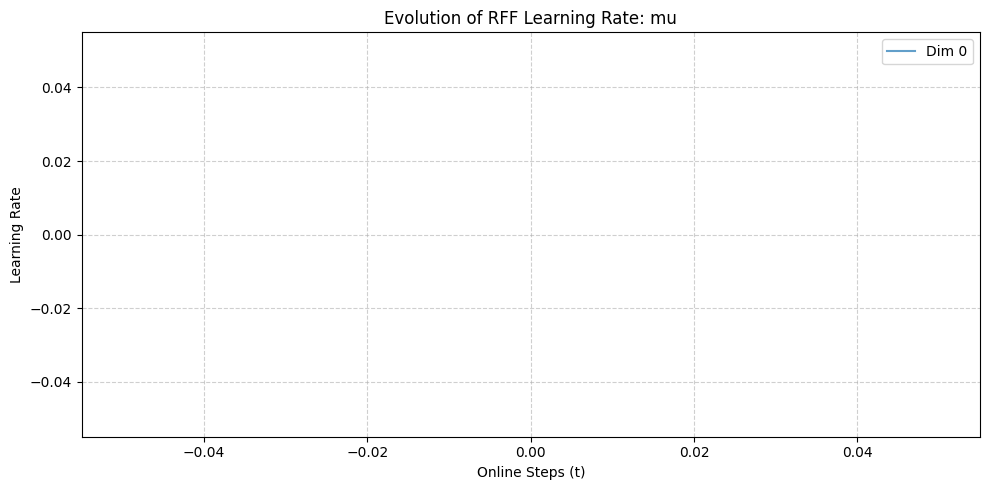

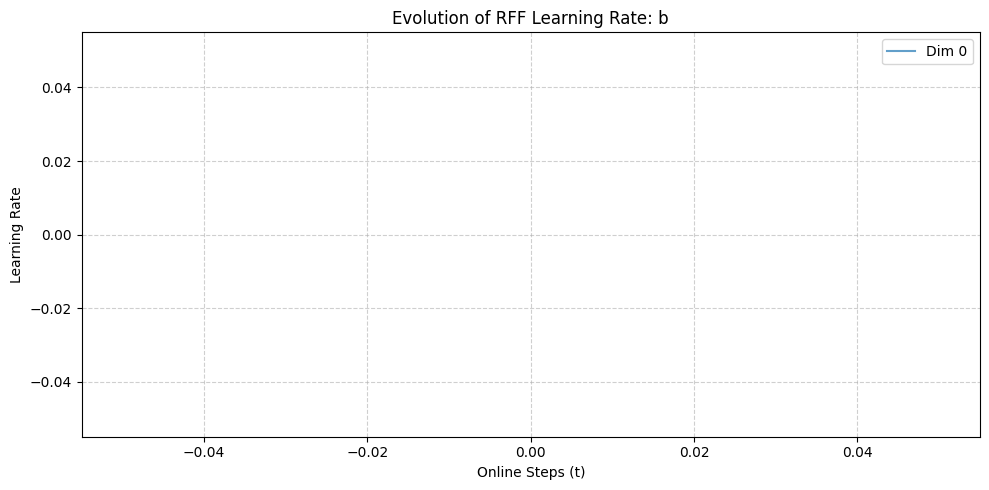

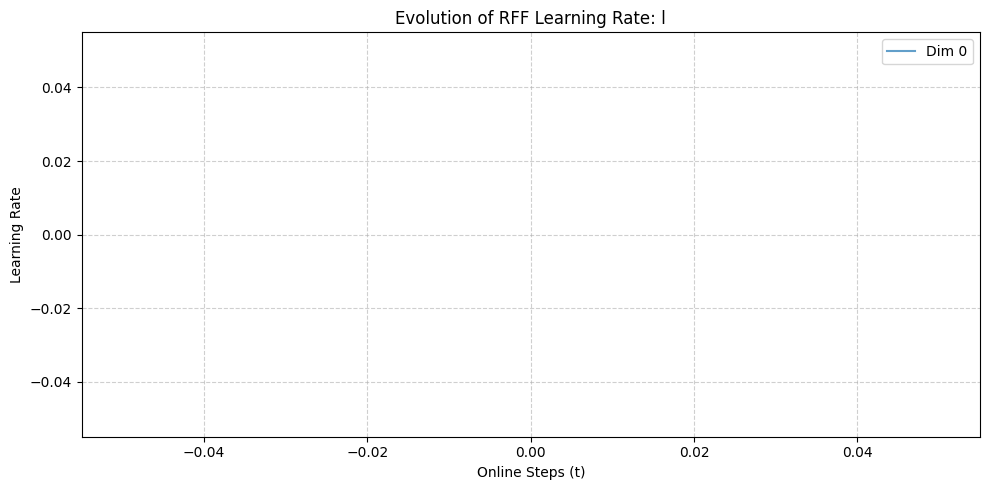

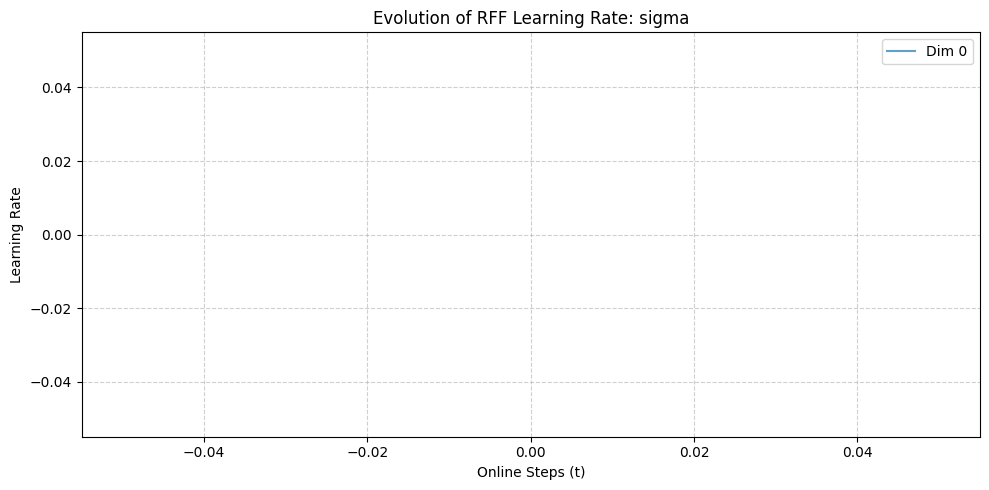

In [7]:
# ============================================================
# 6. Plots (results of the last seed)
# ============================================================
print(f"Plotting learning rate evolution (seed={seeds[-1]})...")
plot_rff_lr_history(last_lr_mu_history,    param_name='mu')
plot_rff_lr_history(last_lr_b_history,     param_name='b')
plot_rff_lr_history(last_lr_l_history,     param_name='l')
plot_rff_lr_history(last_lr_sigma_history, param_name='sigma')

Plotting parameter evolution...


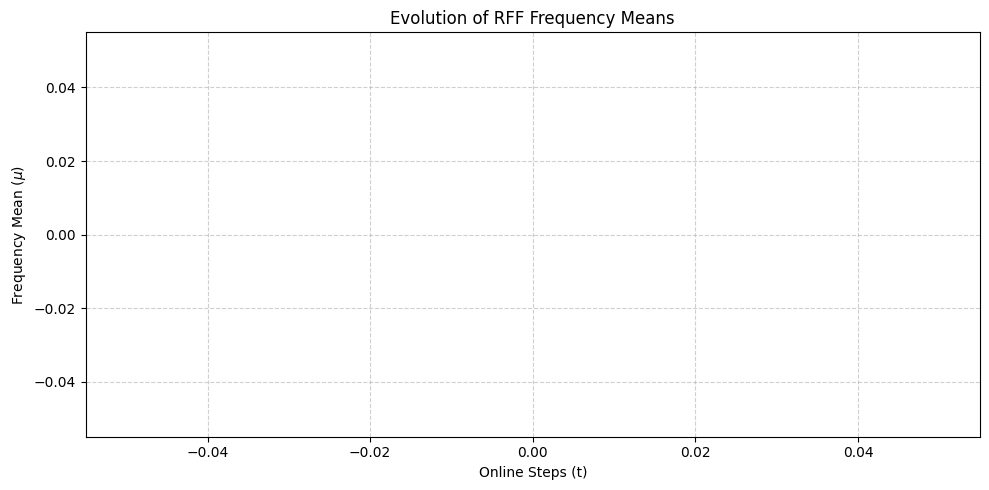

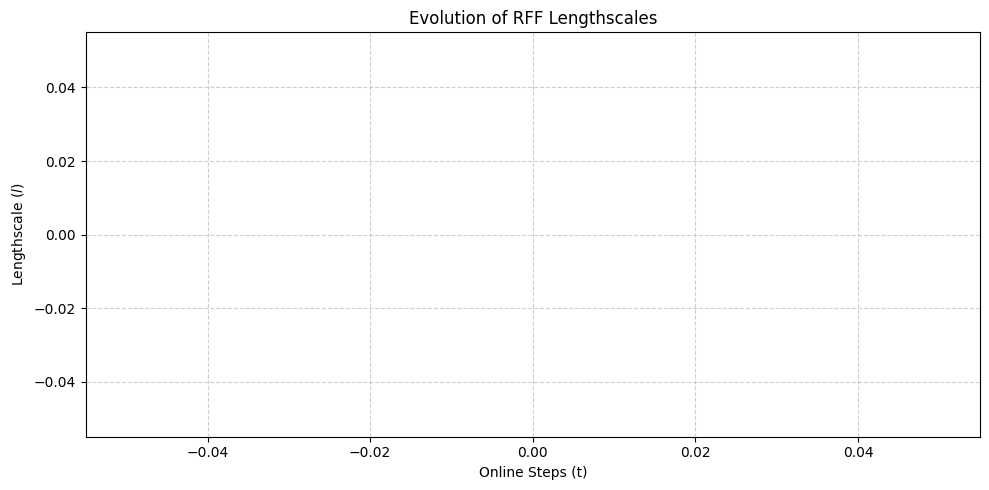

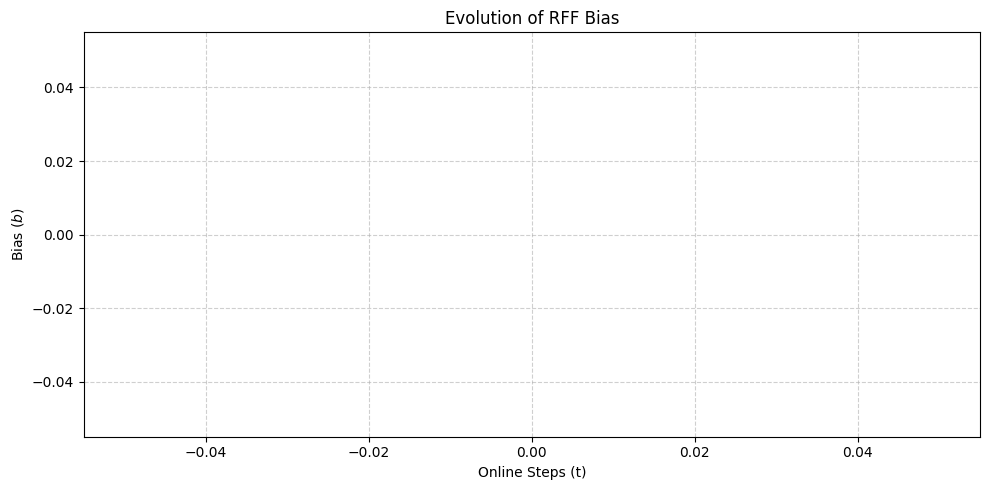

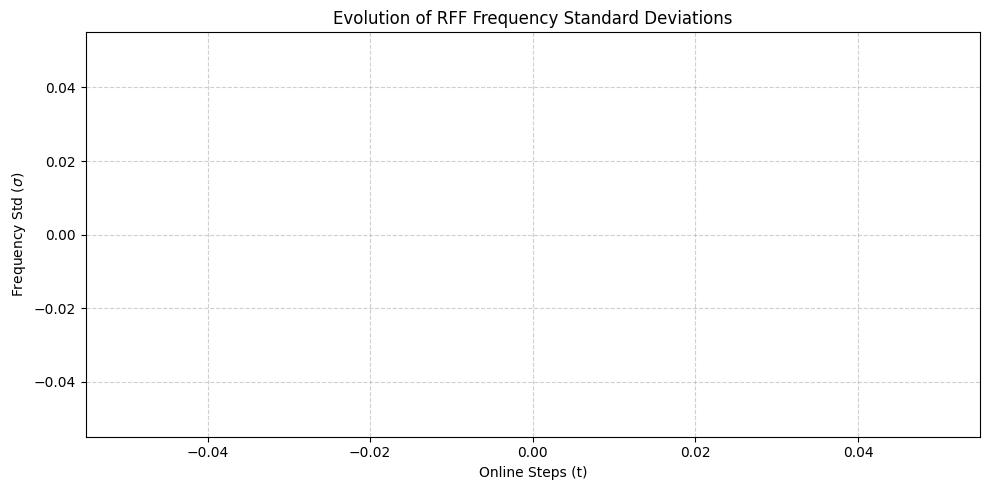

In [8]:
print("Plotting parameter evolution...")
plot_rff_parameters(last_mu_history,        param_type='mu')
plot_rff_parameters(last_log_l_history,     param_type='l')
plot_rff_parameters(last_b_history,         param_type='b')
plot_rff_parameters(last_log_sigma_history, param_type='sigma')

Plotting train predictions vs. actual...


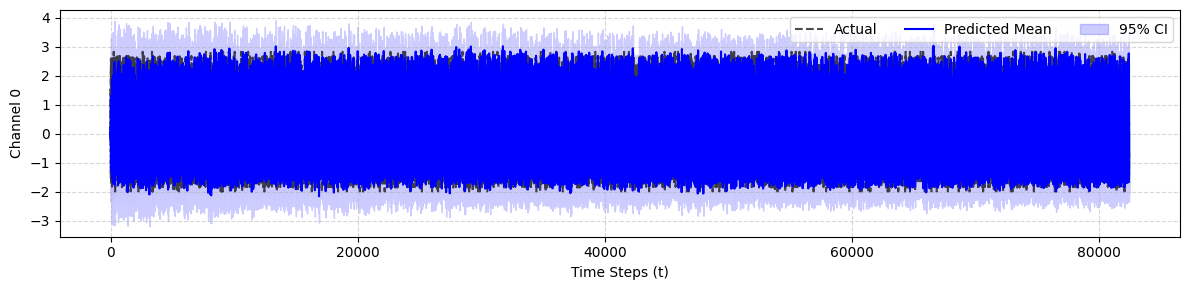

In [9]:
print("Plotting train predictions vs. actual...")
plot_predictions_from_mc(
    y_hat_mc_history=last_predictions_history,
    total_var_history=last_total_var_history,
    actual_data=last_y_train,
    channels=[0],
    last_steps=last_y_train.shape[0]
)

Plotting loss evolution...


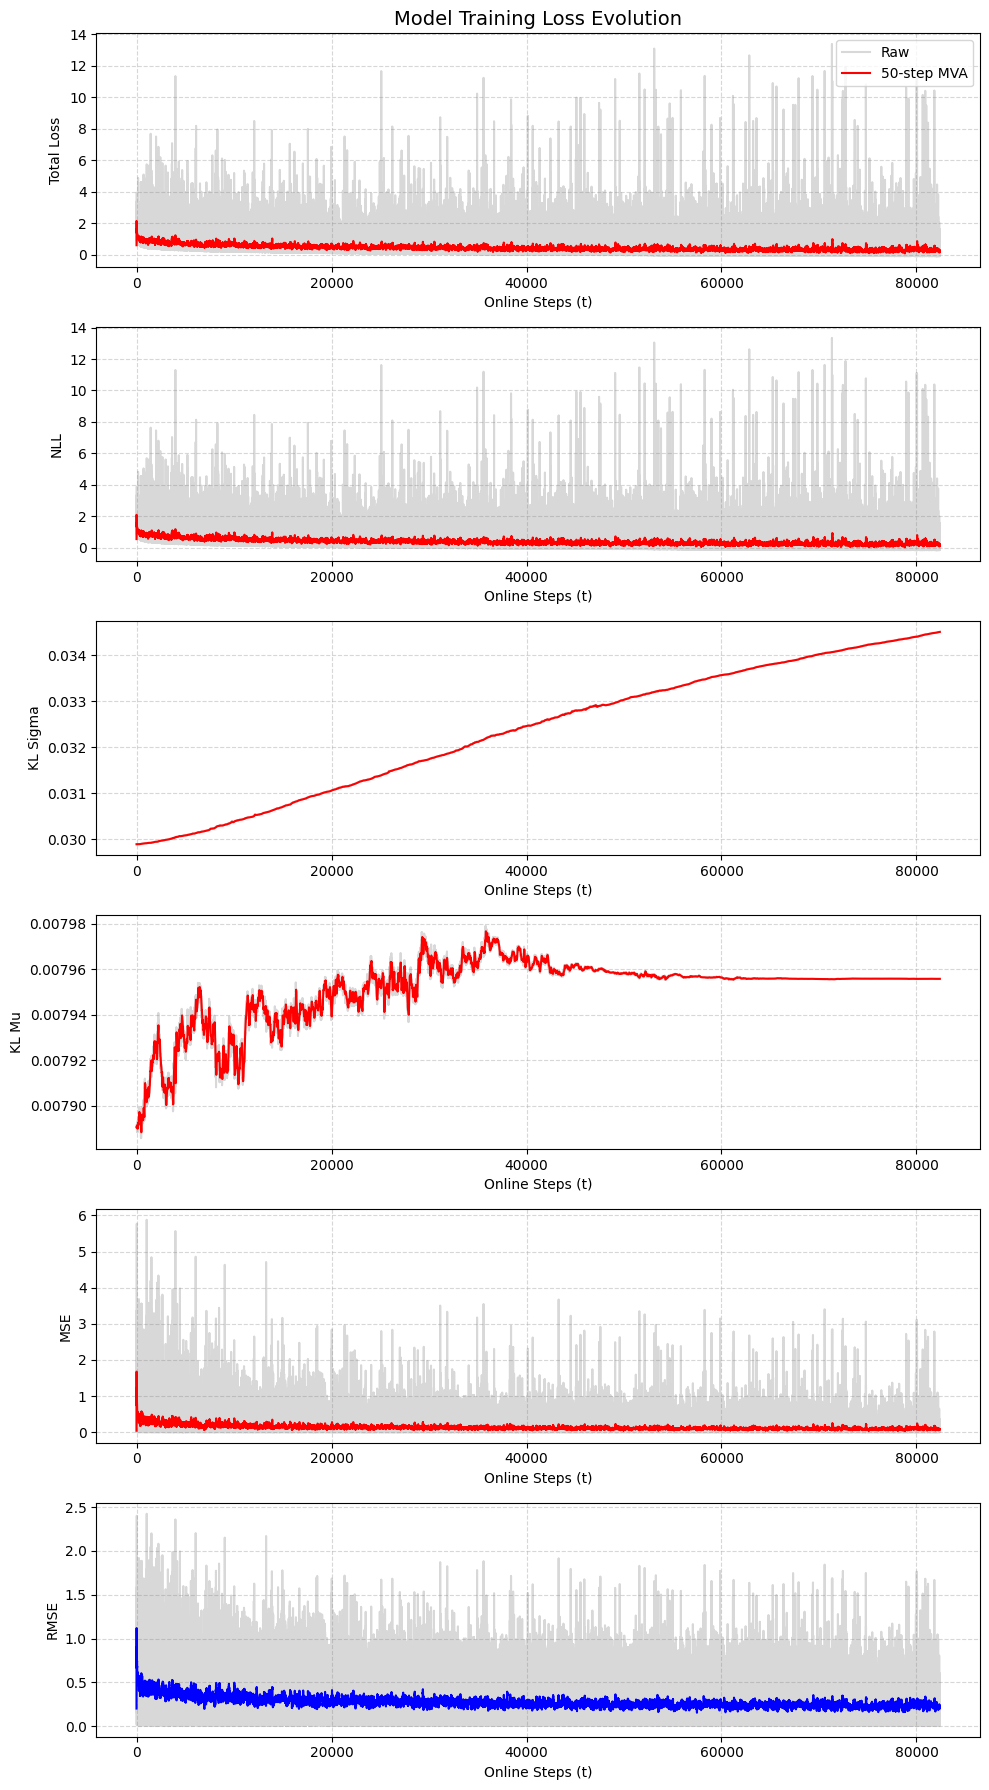

In [10]:
print("Plotting loss evolution...")
plot_loss_evolution(
    loss_history=last_losses_history,
    mva_step=50,
)